

# MODULE 34 — SPEECH PROCESSING

# 34.5 Noise & Audio Enhancement

This is where we learn how to take a speech recording contaminated by traffic, wind, electrical interference or microphone noise and improve its quality before feeding it into an ML/DL model.

Think about your Speech-to-Text system:

- A person speaks near a traffic signal.
- The microphone captures both speech and traffic noise.
- The ASR model receives the noisy recording.
- Recognition accuracy may decrease.

Our job is to understand how to identify and reduce that noise.

---

## 1. Why Do We Need Noise Reduction?

Consider a recording:

### Clean speech

Speech signal with relatively little unwanted interference.

### Noisy speech

Speech mixed with unwanted background signals.

The microphone does not understand which sound is useful and which sound is unwanted. It records the combined acoustic signal.

We can represent this as:

$$
x(t)=s(t)+n(t)
$$

Where:

- $x(t)$ = Observed noisy audio.
- $s(t)$ = Original clean speech.
- $n(t)$ = Unwanted noise.

Our objective is to estimate the original speech from the observed noisy recording.

$$
\hat{s}(t)=\text{NoiseReduction}(x(t))
$$

Here, $\hat{s}(t)$ is the estimated enhanced speech.

**An important point:** Noise reduction does not always recover the exact original speech. Aggressive processing can remove useful speech information too.

---

## 2. Types of Noise

Noise can originate from the environment, recording equipment or the surrounding acoustic space.

### 2.1 Background Noise

Unwanted sounds present during speech recording.

Examples:

- People talking.
- Fans and air conditioners.
- Television.
- Office activity.

**Industry applications:**

- Meeting transcription.
- Voice assistants.
- Call-centre recordings.

### 2.2 White Noise

White noise contains approximately equal power per unit frequency across its defined frequency range.

Its ideal power spectral density is:

$$
S_n(f)=\frac{N_0}{2}
$$

This is for a two-sided power spectral density convention.

Examples:

- Electronic hiss.
- Broadband noise generated during testing.

**Remember:** White noise is a mathematical model, not necessarily the exact behaviour of real-world microphone noise.

### 2.3 Gaussian Noise

Gaussian noise describes noise whose amplitude values follow a normal probability distribution.

$$
n\sim\mathcal{N}(\mu,\sigma^2)
$$

Where:

- $\mu$ = Mean (often assumed zero).
- $\sigma^2$ = Variance.
- $\sigma$ = Standard deviation.

A common simulation is to add random Gaussian noise to clean speech.

### 2.4 Traffic Noise

Examples:

- Vehicle engines.
- Horns.
- Tyres.
- Road traffic.

Traffic noise is often **non-stationary**: its intensity and frequency content change over time.

### 2.5 Wind Noise

Wind hitting the microphone produces unwanted acoustic pressure fluctuations.

It frequently produces strong low-frequency disturbances.

### 2.6 Microphone Noise

Noise originating from the microphone and its electronic circuitry.

Examples:

- Self-noise.
- Preamplifier noise.
- Recording hiss.

### 2.7 Electrical Interference

Unwanted signals introduced through electrical equipment.

Examples:

- Power supply interference.
- Electromagnetic interference.
- Ground loops.
- 50 Hz mains hum in India.

### 2.8 Reverberation and Echo

These are related but distinct acoustic effects.

**Reverberation**

Multiple reflections cause sound to persist after the source stops.

**Echo**

A delayed reflected sound that may be perceived as a separate repetition.

**Important distinction:** Reverberation and echo are not necessarily random noise. They are distortions of the original acoustic signal.

---

## 3. Signal-to-Noise Ratio (SNR)

<badge color="success">Must Know</badge>

Before reducing noise, we need a way to measure how much noise exists in a recording.

This is where **Signal-to-Noise Ratio (SNR)** comes in.

SNR measures the strength of the desired signal relative to unwanted noise.

$$
SNR=10\log_{10}\left(\frac{P_s}{P_n}\right)
$$

Where:

- $P_s$ = Signal power.
- $P_n$ = Noise power.

For discrete audio samples:

$$
P_s=\frac{1}{N}\sum_{i=1}^{N}s_i^2
$$

$$
P_n=\frac{1}{N}\sum_{i=1}^{N}n_i^2
$$

Therefore:

$$
SNR=10\log_{10}\left(
\frac{\sum_{i=1}^{N}s_i^2}
{\sum_{i=1}^{N}n_i^2}
\right)
$$

Here, both signals must cover the same number of samples.

### Understanding SNR values

| SNR | Interpretation |
|---:|---|
| 30 dB | Relatively clean |
| 20 dB | Low noise |
| 10 dB | Noticeable noise |
| 0 dB | Equal signal and noise power |
| -5 dB | Noise power exceeds signal power |

These are illustrative conditions, not universal speech-quality thresholds.

### Example

Suppose:

- Speech power = 100.
- Noise power = 10.

$$
SNR=10\log_{10}(100/10)
$$

$$
SNR=10\log_{10}(10)
$$

$$
\boxed{SNR=10\text{ dB}}
$$

If noise power increases to 100:

$$
SNR=10\log_{10}(100/100)
$$

$$
\boxed{SNR=0\text{ dB}}
$$

The noise now has equal power to the speech.

**Remember:** Higher SNR generally means a cleaner signal, but SNR alone cannot describe speech intelligibility or perceived quality.

---

## 4. Noise Reduction Techniques

There are several ways to reduce noise. Let's understand the techniques in your syllabus.

### 4.1 Noise Identification

Before applying a filter, identify the type of noise.

We can inspect:

- Waveform.
- Spectrogram.
- Frequency spectrum.
- Noise-only portions of the recording.
- Listening tests.

For example:

| Observation | Possible noise |
|---|---|
| Continuous low-frequency disturbance | Wind or engine noise |
| Constant broadband hiss | Electronic noise |
| Narrow frequency peak at 50 Hz | Electrical hum |
| Delayed repetitions | Echo |
| Sound continuing after speech | Reverberation |

These are clues, not definitive classifications.

### 4.2 Noise Suppression

Noise suppression attempts to reduce unwanted components while preserving speech.

General workflow:

```text
Noisy Audio
     |
     ↓
Analyze Audio
     |
     ↓
Identify Noise
     |
     ↓
Noise Suppression
     |
     ↓
Enhanced Audio
```

Two broad approaches:

- Traditional signal-processing methods.
- Deep-learning-based noise suppression.

Traditional approaches include spectral subtraction and filtering.

Modern approaches can use neural networks trained on noisy-clean speech pairs.

### 4.3 Spectral Subtraction

<badge color="success">Must Know</badge>

This is an important classical noise-reduction technique.

**Intuition:**

Suppose we have a recording containing speech and background noise.

We first estimate the noise spectrum using a portion of the recording containing only noise.

Then we subtract the estimated noise spectrum from the noisy speech spectrum.

The process:

**Step 1 — Convert audio into frequency representation**

We use Short-Time Fourier Transform (STFT).

$$
X(m,k)=STFT(x(t))
$$

Where:

- $m$ = Time frame.
- $k$ = Frequency bin.

**Step 2 — Estimate noise spectrum**

$$
\hat{N}(k)
$$

Usually estimated from noise-only frames.

**Step 3 — Subtract noise**

A simplified magnitude spectral subtraction equation:

$$
|\hat{S}(m,k)|=
\max\left(
|X(m,k)|-\alpha|\hat{N}(k)|,
0
\right)
$$

Where:

- $X$ = Noisy spectrum.
- $\hat{N}$ = Estimated noise spectrum.
- $\alpha$ = Noise reduction factor.
- $\hat{S}$ = Estimated clean spectrum.

**Step 4 — Reconstruct audio**

Use the original noisy phase as an approximation and apply inverse STFT.

$$
\hat{s}(t)=ISTFT(\hat{S}(m,k))
$$

**Limitation:** Aggressive subtraction can create musical noise artifacts and distort speech.

### 4.4 Filtering

Filtering removes or attenuates selected frequency components.

There are three important filter types.

#### A. Low-pass filter

Allows low frequencies to pass and attenuates high frequencies.

Applications:

- Reducing high-frequency hiss.
- Removing unwanted high-frequency interference.

#### B. High-pass filter

Allows high frequencies to pass and attenuates low frequencies.

Applications:

- Reducing low-frequency wind rumble.
- Removing microphone handling noise.
- Reducing low-frequency hum components.

#### C. Band-pass filter

Allows a selected frequency range to pass while attenuating frequencies outside that range.

Applications:

- Isolating a desired speech-frequency region.
- Removing unwanted low and high-frequency components.

For example, a speech-oriented band-pass filter might use a range of 100–4000 Hz for a particular experiment.

However, this is not a universal speech filter. The correct range depends on the application and desired speech information.

### Filter comparison

| Filter | Passes | Attenuates |
|---|---|---|
| Low-pass | Below cutoff | Above cutoff |
| High-pass | Above cutoff | Below cutoff |
| Band-pass | Between two cutoffs | Outside the range |

**Important:** Filtering cannot distinguish speech from noise when they occupy overlapping frequency ranges.

---

## 5. Audio Normalization

Normalization adjusts the amplitude of an audio recording.

Suppose your recording has very low amplitude.

We can increase its amplitude to use more of the available digital range.

A simple peak normalization equation:

$$
y[n]=\frac{x[n]}{\max(|x[n]|)}
$$

For a target peak amplitude $A$:

$$
y[n]=A\frac{x[n]}{\max(|x[n]|)}
$$

### Example

If the maximum amplitude is 0.2 and our target is 0.9:

$$
Gain=\frac{0.9}{0.2}
$$

$$
\boxed{Gain=4.5}
$$

Every sample is multiplied by 4.5.

### Important distinction

- Normalization changes amplitude.
- Noise reduction attempts to reduce unwanted noise.

**Normalization does not improve the SNR** because it amplifies speech and noise together.

---

## 6. Clipping Detection

Clipping occurs when an audio signal exceeds the permitted amplitude range of the recording system.

For normalized floating-point audio, the typical amplitude range is:

$$
-1\leq x[n]\leq1
$$

If the signal exceeds the supported range during recording, its peaks may become flattened.

Clipping causes:

- Distortion.
- Loss of waveform information.
- Unnatural sound.
- Potential reduction in ASR performance.

### A simple clipping detector

```python
import numpy as np

threshold = 0.999

clipped_samples = np.sum(
    np.abs(audio) >= threshold
)

clipping_percentage = (
    clipped_samples / len(audio)
) * 100

print("Clipped samples:", clipped_samples)
print("Clipping percentage:", clipping_percentage)
```

This is a simple peak-based detector. It may miss clipping that happened earlier in the recording chain or has been scaled down afterward.

---


In [1]:
import numpy as np
import librosa
import soundfile as sf
import matplotlib.pyplot as plt

audio_path = "example.mp3"

audio, sr = librosa.load(
    audio_path,
    sr=16000,
    mono=True
)

print("Sampling rate:", sr)
print("Duration:", len(audio) / sr)
print("Shape:", audio.shape)

Sampling rate: 16000
Duration: 2.769
Shape: (44304,)


In [2]:
# adding gaussian noise 

def add_gaussian_noise(audio, target_snr_db):

    signal_power = np.mean(audio ** 2)

    noise = np.random.normal(
        0,
        1,
        len(audio)
    )

    noise_power = np.mean(noise ** 2)

    target_noise_power = (
        signal_power / (10 ** (target_snr_db / 10))
    )

    noise = noise * np.sqrt(
        target_noise_power / noise_power
    )

    noisy_audio = audio + noise

    return noisy_audio


noisy_audio = add_gaussian_noise(audio, 10)

In [3]:
from IPython.display import Audio, display

print("Original Audio")
display(Audio(audio, rate=sr))

print("Noisy Audio")
display(Audio(noisy_audio, rate=sr))

Original Audio


Noisy Audio


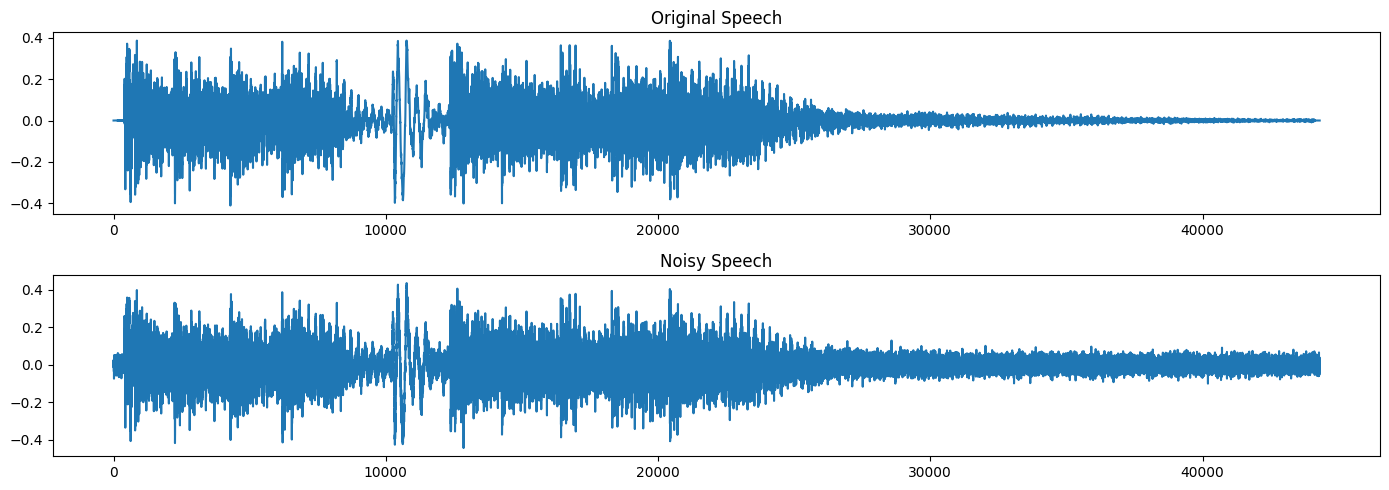

In [4]:
plt.figure(figsize=(14, 5))

plt.subplot(2, 1, 1)
plt.plot(audio)
plt.title("Original Speech")

plt.subplot(2, 1, 2)
plt.plot(noisy_audio)
plt.title("Noisy Speech")

plt.tight_layout()
plt.show()

In [5]:
# Apply a band-pass filter

from scipy.signal import butter, sosfiltfilt

def bandpass_filter(audio, sr, lowcut, highcut):

    sos = butter(
        4,
        [lowcut, highcut],
        btype="bandpass",
        fs=sr,
        output="sos"
    )

    filtered_audio = sosfiltfilt(sos, audio)

    return filtered_audio


filtered_audio = bandpass_filter(
    noisy_audio,
    sr,
    100,
    4000
)

In [6]:
# Apply spectral subtraction

from scipy.signal import stft, istft

def spectral_subtraction(audio, sr, noise_duration=0.5, alpha=1.5):

    frequencies, times, Zxx = stft(
        audio,
        fs=sr,
        nperseg=512,
        noverlap=384
    )

    # Estimate noise magnitude
    noise_frames = times <= noise_duration

    noise_magnitude = np.mean(
        np.abs(Zxx[:, noise_frames]),
        axis=1,
        keepdims=True
    )

    # Subtract estimated noise
    magnitude = np.abs(Zxx)

    enhanced_magnitude = np.maximum(
        magnitude - alpha * noise_magnitude,
        0
    )

    # Preserve noisy signal phase
    phase = np.exp(1j * np.angle(Zxx))

    enhanced_spectrum = enhanced_magnitude * phase

    # Reconstruct audio
    _, enhanced_audio = istft(
        enhanced_spectrum,
        fs=sr,
        nperseg=512,
        noverlap=384
    )

    return enhanced_audio


enhanced_audio = spectral_subtraction(
    noisy_audio,
    sr
)

In [7]:
print("Original")
display(Audio(audio, rate=sr))

print("Noisy")
display(Audio(noisy_audio, rate=sr))

print("Bandpass Filtered")
display(Audio(filtered_audio, rate=sr))

print("Spectral Subtraction")
display(Audio(enhanced_audio, rate=sr))

Original


Noisy


Bandpass Filtered


Spectral Subtraction


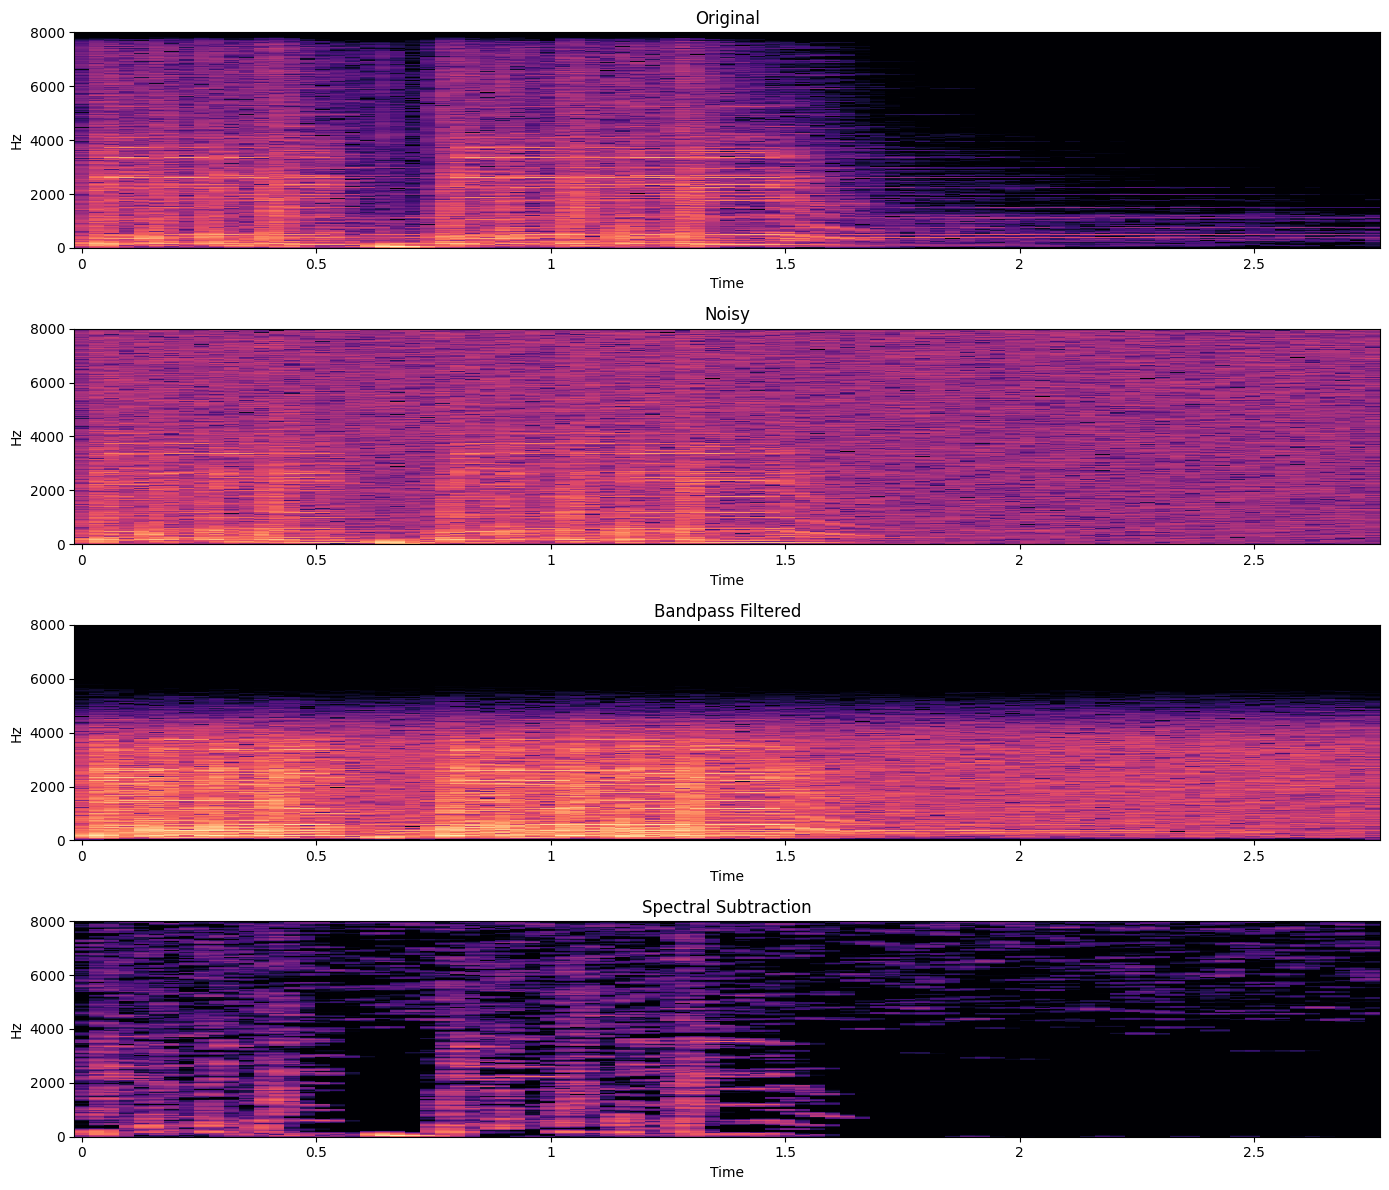

In [8]:
signals = [
    audio,
    noisy_audio,
    filtered_audio,
    enhanced_audio
]

titles = [
    "Original",
    "Noisy",
    "Bandpass Filtered",
    "Spectral Subtraction"
]

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

for ax, signal, title in zip(axes, signals, titles):

    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(signal)),
        ref=np.max
    )

    librosa.display.specshow(
        D,
        sr=sr,
        x_axis="time",
        y_axis="hz",
        ax=ax
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()